# Лаба 3: упражнения. Train/test, валидация и линейная регрессия

Тренировочный ноутбук по данным о продажах домов в Эймсе (`SalePrice` - цена продажи). Задания повторяют разбор из учебного ноутбука, плюс несколько вопросов на понимание. Ответов здесь нет, нужно сделать самому.

## Подготовка

In [1]:
try:
    from sklearnex import patch_sklearn, unpatch_sklearn
    patch_sklearn()
    sklearnex_available = True
except ImportError:
    sklearnex_available = False
    print('sklearnex не установлен, работает обычный scikit-learn')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler

%matplotlib inline
pd.set_option('display.max_columns', 60)
data_path = os.path.join('data', 'Ames_Housing_Sales.csv')

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Загрузите данные с помощью Pandas и посмотрите на их структуру (79 признаков и целевая переменная `SalePrice`).
* Сколько столбцов каждого типа: `int64`, `float64`, строковые (`object`/`str`)?

Подсказка: в новых версиях pandas строки могут иметь тип `str`, а не `object`.

In [2]:
data = pd.read_csv(data_path, keep_default_na=False)
print('форма:', data.shape)
print('пропусков:', data.isna().sum().sum())
data.head()

форма: (1379, 80)
пропусков: 0


,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,BsmtFinType1,BsmtFinType2,BsmtFullBath,BsmtHalfBath,BsmtQual,BsmtUnfSF,CentralAir,Condition1,Condition2,Electrical,EnclosedPorch,ExterCond,ExterQual,Exterior1st,Exterior2nd,Fence,FireplaceQu,Fireplaces,Foundation,FullBath,...,LotShape,LowQualFinSF,MSSubClass,MSZoning,MasVnrArea,MasVnrType,MiscFeature,MiscVal,MoSold,Neighborhood,OpenPorchSF,OverallCond,OverallQual,PavedDrive,PoolArea,PoolQC,RoofMatl,RoofStyle,SaleCondition,SaleType,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,None,3,1Fam,TA,No,706.0,0.0,GLQ,Unf,1,0,Gd,150.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,None,None,0,PConc,2,...,Reg,0.0,60,RL,196.0,BrkFace,None,0.0,2,CollgCr,61.0,5,7,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,None,3,1Fam,TA,Gd,978.0,0.0,ALQ,Unf,0,1,Gd,284.0,Y,Feedr,Norm,SBrkr,0.0,TA,TA,MetalSd,MetalSd,None,TA,1,CBlock,2,...,Reg,0.0,20,RL,0.0,None,None,0.0,5,Veenker,0.0,8,6,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,None,3,1Fam,TA,Mn,486.0,0.0,GLQ,Unf,1,0,Gd,434.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,None,TA,1,PConc,2,...,IR1,0.0,60,RL,162.0,BrkFace,None,0.0,9,CollgCr,42.0,5,7,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,None,3,1Fam,Gd,No,216.0,0.0,ALQ,Unf,1,0,TA,540.0,Y,Norm,Norm,SBrkr,272.0,TA,TA,Wd Sdng,Wd Shng,None,Gd,1,BrkTil,1,...,IR1,0.0,70,RL,0.0,None,None,0.0,2,Crawfor,35.0,5,7,Y,0.0,None,CompShg,Gable,Abnorml,WD,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,None,4,1Fam,TA,Av,655.0,0.0,GLQ,Unf,1,0,Gd,490.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,None,TA,1,PConc,2,...,IR1,0.0,60,RL,350.0,BrkFace,None,0.0,12,NoRidge,84.0,5,8,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


In [3]:
print(data.dtypes.value_counts(), end='\n\n')

cat_cols = data.select_dtypes(exclude='number').columns
num_cols = data.select_dtypes(include='number').columns.drop('SalePrice')
print(f'строковых признаков: {len(cat_cols)}, числовых признаков: {len(num_cols)}, плюс цель SalePrice')

str        43
float64    21
int64      16
Name: count, dtype: int64

строковых признаков: 43, числовых признаков: 36, плюс цель SalePrice


In [4]:
raw = pd.read_csv(data_path)
na = raw.isna().sum()
print('пропусков при чтении по умолчанию:', na.sum())
na[na > 0].sort_values(ascending=False)

пропусков при чтении по умолчанию: 8657


PoolQC          1372
MiscFeature     1328
Alley           1297
Fence           1114
MasVnrType       797
FireplaceQu      618
BsmtFinType2     427
BsmtExposure     426
BsmtCond         426
BsmtQual         426
BsmtFinType1     426
dtype: int64

In [5]:
print(data['SalePrice'].describe().round(0))
print('асимметрия SalePrice:', round(data['SalePrice'].skew(), 2))

count      1379.0
mean     185480.0
std       79024.0
min       35311.0
25%      134000.0
50%      167500.0
75%      217750.0
max      755000.0
Name: SalePrice, dtype: float64
асимметрия SalePrice: 1.94


**Ответ.**

В наборе 1379 домов и 80 столбцов: 79 признаков и цель `SalePrice`. По типам 43 строковых столбца (в pandas 3 их тип `str`, в учебном ноутбуке `object`), 21 `float64` и 16 `int64`. Если не считать `SalePrice`, числовых признаков 36.

Здесь есть ловушка: строка `"None"` в этих данных значит «нет» (нет аллеи, бассейна, забора, камина). pandas 2+ по умолчанию читает `"None"` как пропуск, и в 11 столбцах появляется 8657 NaN, хотя пропусков на самом деле нет. Поэтому читаю с `keep_default_na=False`. Иначе `nunique()` не посчитает «None» за категорию, и в вопросе 2 получится 204 вместо 215.

Цена продажи от 35 до 755 тыс. долларов, медиана 167.5 тыс., среднее 185.5 тыс. Распределение скошено вправо (skew 1.94): немного очень дорогих домов тянут среднее вверх.

## Вопрос 2

Строковые (категориальные) признаки нужно кодировать. Неупорядоченные категории кодируют one-hot, порядковые - числами по порядку.

* Выберите строковые столбцы.
* Сколько новых столбцов получится, если закодировать их все one-hot (на каждый признак `n - 1` столбцов, где `n` - число категорий; признаки с одной категорией не кодируем)?
* Сколько всего будет признаков по сравнению с текущим числом?

In [6]:
n_cat = data[cat_cols].nunique().sort_values(ascending=False)
print(n_cat.head(10).to_string(), end='\n\n')

ohc_extra = n_cat[n_cat > 1] - 1
print('признаков с одной категорией:', (n_cat == 1).sum())
print('one-hot столбцов (сумма n - 1):', ohc_extra.sum())

n_features = data.shape[1] - 1
n_after = n_features - len(cat_cols) + ohc_extra.sum()
print(f'признаков сейчас: {n_features}, после one-hot (n - 1): {n_after}, то есть в {n_after / n_features:.1f} раза больше')

Neighborhood    25
Exterior2nd     16
Exterior1st     14
SaleType         9
Condition1       9
RoofMatl         8
HouseStyle       8
Condition2       8
Functional       7
BsmtFinType2     7

признаков с одной категорией: 0
one-hot столбцов (сумма n - 1): 215
признаков сейчас: 79, после one-hot (n - 1): 251, то есть в 3.2 раза больше


In [7]:
raw_cat = raw.select_dtypes(exclude='number').nunique()
print('one-hot столбцов при чтении по умолчанию:', (raw_cat[raw_cat > 1] - 1).sum())

one-hot столбцов при чтении по умолчанию: 204


**Ответ.**

Больше всего категорий у `Neighborhood` (25 районов), `Exterior2nd` (16) и `Exterior1st` (14). Признаков с одной категорией нет, так что кодировать нужно все 43.

One-hot дает на признак n - 1 столбец, всего 215. Вместо 43 строковых столбцов будет 215, и признаков станет 79 - 43 + 215 = **251**, в 3.2 раза больше, чем сейчас. При этом домов всего 1379, а в train после разбиения 965. Признаков становится около четверти от числа строк. Кроме того, столбцы одного признака жестко связаны: в каждой строке ровно одна единица. Это та проблема из лекции, про которую говорит задание: признаков много, и они сильно коррелируют друг с другом.

## Вопрос 3

Создайте два набора данных:

* `data_ohc` - копия (`.copy()`), где каждый строковый признак закодирован one-hot (сначала `LabelEncoder`, потом `OneHotEncoder`), исходные столбцы удалены;
* `data` - набор, где строковые столбцы просто удалены.

Сравните форму (`shape`) обоих наборов. Когда вместо `LabelEncoder` лучше использовать `DictVectorizer`?

In [8]:
data_ohc = data.copy()
le = LabelEncoder()
ohc = OneHotEncoder()

for col in n_cat.index:
    codes = le.fit_transform(data_ohc[col])
    data_ohc = data_ohc.drop(columns=col)
    new_dat = ohc.fit_transform(codes.reshape(-1, 1))
    col_names = [f'{col}_{c}' for c in le.classes_]
    new_df = pd.DataFrame(new_dat.toarray(), index=data_ohc.index, columns=col_names)
    data_ohc = pd.concat([data_ohc, new_df], axis=1)

data = data.drop(columns=cat_cols)

print('data_ohc:', data_ohc.shape)
print('data:    ', data.shape)
print('data_ohc шире исходных 80 столбцов на', data_ohc.shape[1] - 80)

data_ohc: (1379, 295)
data:     (1379, 37)
data_ohc шире исходных 80 столбцов на 215


In [9]:
nb_cols = [c for c in data_ohc.columns if c.startswith('Neighborhood_')]
print(len(nb_cols), 'столбцов, сумма по строке:', data_ohc[nb_cols].sum(axis=1).unique())
data_ohc[nb_cols[:6]].head()

25 столбцов, сумма по строке: [1.]


,Neighborhood_Blmngtn,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr
0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0


**Ответ.**

`data_ohc` получился 1379 x 295, `data` 1379 x 37 (36 числовых признаков и `SalePrice`). `data_ohc` шире исходной таблицы на 215 столбцов, как и посчитано в вопросе 2. Как и в учебном ноутбуке, на признак с n категориями создается n столбцов, а исходный удаляется, то есть +(n - 1) на признак. Значит, внутри каждого признака столбцы в сумме дают 1 в каждой строке (видно на `Neighborhood`). В вопросе 4 это всплывет.

`LabelEncoder` просто нумерует категории по алфавиту. Номер сам по себе ничего не значит, поэтому сразу после него идет one-hot. `DictVectorizer` удобнее в двух случаях:
- данные приходят как список словарей (JSON, логи, записи с разным набором полей). Он за один проход кодирует one-hot все строковые значения, числа оставляет как есть и сразу выдает разреженную матрицу, без цикла по столбцам;
- для порядковых признаков нужно задать свое число каждой категории. Например, у `ExterQual` и `KitchenQual` порядок Po < Fa < TA < Gd < Ex, и их лучше закодировать числами 1..5: эти числа записываются в словари, и `DictVectorizer` оставит их одним числовым столбцом. LabelEncoder такой порядок не знает (у него Ex = 0, Fa = 1, Gd = 2 по алфавиту), а one-hot порядок просто теряет.

## Вопрос 4

* Разбейте оба набора на train и test (одинаковый `random_state`, например `test_size=0.3, random_state=42`). Проверьте, что индексы совпадают.
* Обучите на каждом базовую `LinearRegression`.
* Посчитайте MSE на train и на test для обеих моделей.

У какой модели ошибка на test меньше и почему? Что случилось с one-hot моделью (переобучение, число признаков против числа строк, dummy trap)?

In [10]:
y_col = 'SalePrice'

X_data, y_data = data.drop(columns=y_col), data[y_col]
X_data_ohc, y_data_ohc = data_ohc.drop(columns=y_col), data_ohc[y_col]

X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.3, random_state=42)
X_train_ohc, X_test_ohc, y_train_ohc, y_test_ohc = train_test_split(X_data_ohc, y_data_ohc,
                                                                    test_size=0.3, random_state=42)

print('индексы train совпадают:', (X_train.index == X_train_ohc.index).all())
print('индексы test совпадают: ', (X_test.index == X_test_ohc.index).all())
print('train:', X_train.shape, X_train_ohc.shape, '  test:', X_test.shape, X_test_ohc.shape)

индексы train совпадают: True
индексы test совпадают:  True
train: (965, 36) (965, 294)   test: (414, 36) (414, 294)


In [11]:
def evaluate(model, Xtr, ytr, Xte, yte):
    pred_tr, pred_te = model.predict(Xtr), model.predict(Xte)
    return {'MSE train': mean_squared_error(ytr, pred_tr),
            'MSE test': mean_squared_error(yte, pred_te),
            'RMSE train, $': np.sqrt(mean_squared_error(ytr, pred_tr)),
            'RMSE test, $': np.sqrt(mean_squared_error(yte, pred_te)),
            'R2 test': r2_score(yte, pred_te)}

LR = LinearRegression().fit(X_train, y_train)
y_test_pred = LR.predict(X_test)

LR_ohc = LinearRegression().fit(X_train_ohc, y_train_ohc)

error_df = pd.DataFrame({'без one-hot': evaluate(LR, X_train, y_train, X_test, y_test),
                         'one-hot': evaluate(LR_ohc, X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc)})
error_df.style.format('{:,.3g}')

,без one-hot,one-hot
MSE train,1.13e+09,3.18e+08
MSE test,1.37e+09,8.22e+09
"RMSE train, $",3.36e+04,1.78e+04
"RMSE test, $",3.7e+04,9.07e+04
R2 test,0.773,-0.362


In [12]:
def rank_info(X):
    A = np.c_[np.ones(len(X)), X.to_numpy(dtype=float)]
    return f'{A.shape[0]} строк, {A.shape[1]} столбцов, ранг {np.linalg.matrix_rank(A)}'

print('без one-hot:', rank_info(X_train))
print('one-hot:    ', rank_info(X_train_ohc), end='\n\n')

dummy_cols = X_train_ohc.columns.difference(X_train.columns)
ones_in_train = X_train_ohc[dummy_cols].sum()
print('one-hot столбцов, где в train одни нули (категория есть только в test):', (ones_in_train == 0).sum())
print('one-hot столбцов, где в train от 1 до 3 единиц:', ones_in_train.between(1, 3).sum(), end='\n\n')

print('GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF:',
      (X_data['GrLivArea'] == X_data['1stFlrSF'] + X_data['2ndFlrSF'] + X_data['LowQualFinSF']).all())
print('TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF:',
      (X_data['TotalBsmtSF'] == X_data['BsmtFinSF1'] + X_data['BsmtFinSF2'] + X_data['BsmtUnfSF']).all())

без one-hot: 965 строк, 37 столбцов, ранг 35
one-hot:     965 строк, 295 столбцов, ранг 232

one-hot столбцов, где в train одни нули (категория есть только в test): 10
one-hot столбцов, где в train от 1 до 3 единиц: 43

GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF: True
TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF: True


In [13]:
if sklearnex_available:
    unpatch_sklearn()
    from sklearn.linear_model import LinearRegression as StockLR
    patch_sklearn(verbose=False)
else:
    StockLR = LinearRegression

data_n1 = pd.get_dummies(pd.read_csv(data_path, keep_default_na=False), columns=list(cat_cols),
                         drop_first=True, dtype=float)
X_train_n1, X_test_n1, y_train_n1, y_test_n1 = train_test_split(data_n1.drop(columns=y_col), data_n1[y_col],
                                                                test_size=0.3, random_state=42)
sets = {'без one-hot': (X_train, y_train, X_test, y_test),
        'one-hot (n столбцов)': (X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc),
        'one-hot (n - 1, drop_first)': (X_train_n1, y_train_n1, X_test_n1, y_test_n1)}
rows = {}
for solver, cls in [('scikit-learn', StockLR), ('sklearnex', LinearRegression)]:
    for name, (a, b, c, d) in sets.items():
        rows[(name, solver)] = evaluate(cls().fit(a, b), a, b, c, d)
print('n - 1:', rank_info(X_train_n1))
pd.DataFrame(rows).T.style.format('{:,.3g}')

n - 1: 965 строк, 252 столбцов, ранг 232


,,MSE train,MSE test,"RMSE train, $","RMSE test, $",R2 test
без one-hot,scikit-learn,1.13e+09,1.37e+09,3.36e+04,3.7e+04,0.773
one-hot (n столбцов),scikit-learn,3.39e+08,1.9e+09,1.84e+04,4.36e+04,0.685
"one-hot (n - 1, drop_first)",scikit-learn,3.43e+08,2.7e+09,1.85e+04,5.19e+04,0.553
без one-hot,sklearnex,1.13e+09,1.37e+09,3.36e+04,3.7e+04,0.773
one-hot (n столбцов),sklearnex,3.18e+08,8.22e+09,1.78e+04,9.07e+04,-0.362
"one-hot (n - 1, drop_first)",sklearnex,3.18e+08,5.25e+09,1.78e+04,7.25e+04,0.13


**Ответ.**

| | без one-hot | one-hot |
|---|---|---|
| RMSE train | 33.6 тыс. $ | 17.8 тыс. $ |
| RMSE test | 37.0 тыс. $ | 90.7 тыс. $ |
| R² test | 0.773 | -0.36 |

На test лучше модель **без one-hot**: MSE 1.37e9, то есть в среднем ошибка около 37 тыс. долларов. One-hot модель на train ошибается в 2 раза меньше (по MSE в 3.6 раза), а на test ее MSE в 6 раз больше, и R² отрицательный, то есть она хуже константы «всегда средняя цена». Это переобучение. Причины:

1. **Признаков слишком много для таких данных.** 294 признака на 965 домов в train. Модель подгоняется под шум конкретных домов.
2. **Редкие категории.** У 43 one-hot столбцов в train всего от 1 до 3 единиц, а у 10 одни нули: категория встречается только в test. Коэффициент для такого столбца по сути угадывается, и на доме из test с этой категорией предсказание улетает.
3. **Dummy trap и неполный ранг.** У матрицы one-hot (с константой) 295 столбцов, а ранг всего 232: 63 линейные зависимости. 43 из них — это dummy trap: столбцы каждого признака в сумме дают 1, то есть повторяют свободный член. Еще 10 дают нулевые столбцы, 2 — числовые признаки (`GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF`, `TotalBsmtSF` = сумма трех площадей подвала), остальные — категории, которые в train всегда встречаются вместе (например, «None» в признаках подвала `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1` стоит у одних и тех же домов). При неполном ранге у задачи бесконечно много решений с одинаковой ошибкой на train, но на test они дают разные предсказания.

Это видно по второй таблице. Без one-hot обычный scikit-learn и Intel Extension дают одно и то же (MSE 1.37e9): две зависимости в числовых признаках выполняются и в test, поэтому предсказания не зависят от выбора решения. А на one-hot разные решатели дают MSE на test 1.9e9 и 8.2e9, хотя данные одни и те же. В учебном ноутбуке вышло вообще 5.9e19, это та же нестабильность на другой версии библиотек. «Честный» one-hot с n - 1 столбцами (`drop_first`) убирает dummy trap, но ранг остается 232 из 252, и на test он все равно хуже модели без one-hot (2.7e9 и 5.3e9). Значит, главная проблема не в dummy trap, а в числе признаков и редких категориях. Лечится это регуляризацией (Ridge, Lasso, это следующая тема), объединением редких категорий или отбором признаков.

## Вопрос 5

Для каждого из двух наборов:

* посчитайте асимметрию (`skew`) числовых признаков и решите, какие нужно преобразовать;
* масштабируйте признаки (но не one-hot колонки) с помощью `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`. Масштабатор обучайте **только на train**, а применяйте и к train, и к test;
* сравните ошибку на test для разных масштабаторов.

Почему масштабирование почти не меняет ошибку обычной линейной регрессии? Для каких методов оно всё-таки важно?

In [14]:
skew = X_train.skew().sort_values(ascending=False)
skewed_cols = skew[skew > 0.75].index
print(f'skew > 0.75: {len(skewed_cols)} из {len(skew)} признаков', end='\n\n')
print(skew.round(2).to_string())

skew > 0.75: 23 из 36 признаков

MiscVal          26.92
PoolArea         15.78
LotArea          11.50
LowQualFinSF     11.21
3SsnPorch        10.15
KitchenAbvGr      5.50
ScreenPorch       4.60
BsmtFinSF2        4.47
BsmtHalfBath      3.88
EnclosedPorch     3.22
LotFrontage       3.14
MasVnrArea        2.49
OpenPorchSF       2.30
BsmtFinSF1        2.01
TotalBsmtSF       1.98
1stFlrSF          1.54
GrLivArea         1.46
MSSubClass        1.40
WoodDeckSF        1.33
OverallCond       0.99
BsmtUnfSF         0.90
GarageArea        0.84
2ndFlrSF          0.77
Fireplaces        0.59
TotRmsAbvGrd      0.55
HalfBath          0.52
BsmtFullBath      0.48
OverallQual       0.28
GarageCars        0.23
MoSold            0.21
YrSold            0.10
BedroomAbvGr      0.09
FullBath          0.04
YearRemodAdd     -0.59
GarageYrBlt      -0.65
YearBuilt        -0.72


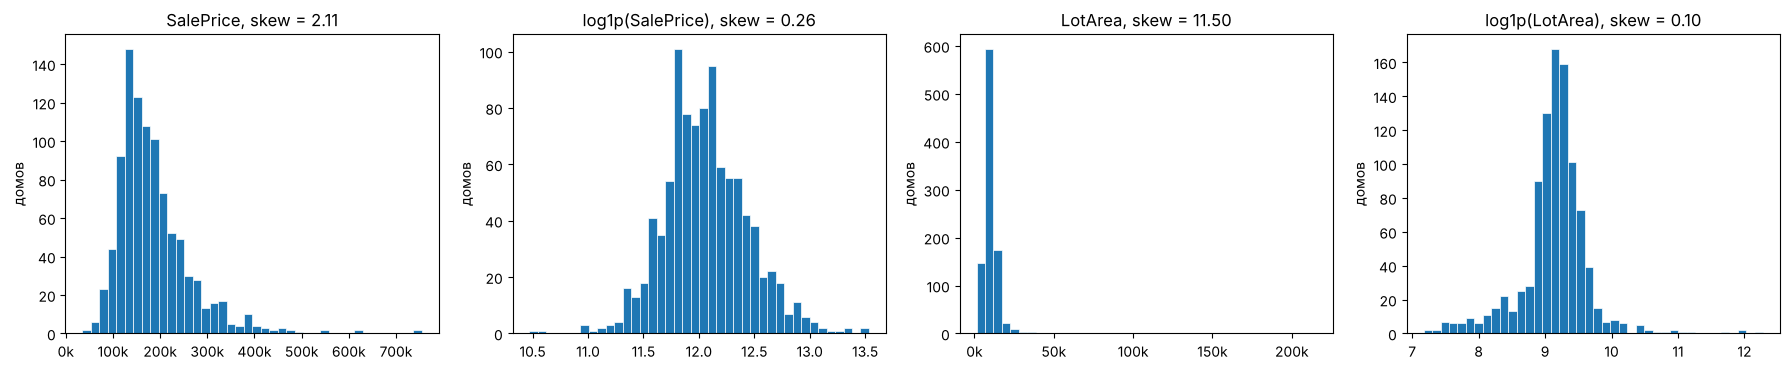

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (title, values) in zip(axes, [('SalePrice', y_train), ('log1p(SalePrice)', np.log1p(y_train)),
                                      ('LotArea', X_train['LotArea']), ('log1p(LotArea)', np.log1p(X_train['LotArea']))]):
    ax.hist(values, bins=40, edgecolor='white', linewidth=0.5)
    ax.set(title=f'{title}, skew = {values.skew():.2f}', ylabel='домов')
for ax in (axes[0], axes[2]):
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k'))
plt.tight_layout()
plt.show()

In [16]:
scalers = {'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler(), 'MaxAbsScaler': MaxAbsScaler()}
scale_cols = X_train.columns

def fit_scaled(a, b, c, scaler):
    A, C = a.copy(), c.copy()
    A[scale_cols] = scaler.fit_transform(A[scale_cols])
    C[scale_cols] = scaler.transform(C[scale_cols])
    return LinearRegression().fit(A, b).predict(C)

errors = {}
for name, (a, b, c, d) in list(sets.items())[:2]:
    errors[(name, 'без масштабирования')] = mean_squared_error(d, LinearRegression().fit(a, b).predict(c))
    for sname, scaler in scalers.items():
        errors[(name, sname)] = mean_squared_error(d, fit_scaled(a, b, c, scaler))

order = ['без масштабирования'] + list(scalers)
pd.Series(errors).unstack(0).loc[order, ['без one-hot', 'one-hot (n столбцов)']].style.format('{:,.6g}')

,без one-hot,one-hot (n столбцов)
без масштабирования,1.37218e+09,8.22004e+09
StandardScaler,1.37218e+09,8.19367e+09
MinMaxScaler,1.37218e+09,8.21971e+09
MaxAbsScaler,1.37218e+09,8.21886e+09


In [17]:
pred_raw = LinearRegression().fit(X_train, y_train).predict(X_test)
pred_std = fit_scaled(X_train, y_train, X_test, StandardScaler())
print('макс. разница предсказаний, $:', np.abs(pred_raw - pred_std).max())

макс. разница предсказаний, $: 0.00024366413708776236


**Ответ.**

**Асимметрия.** У 23 из 36 признаков skew > 0.75. Сильнее всего скошены `MiscVal` (26.9), `PoolArea` (15.8), `LotArea` (11.5), `LowQualFinSF` (11.2), `3SsnPorch` (10.2): у большинства домов там 0 или небольшое значение, и есть несколько огромных. Площади и цену имеет смысл логарифмировать (вопрос 7): на гистограмме `log1p(LotArea)` skew падает с 11.5 до 0.1, у `SalePrice` с 2.1 до 0.26. Но не все из 23 признаков стоит трогать:
- `MSSubClass` (1.40) — на самом деле категория (тип здания закодирован числами 20, 60, 120...), как `area_code` в лабе 2, логарифм для нее бессмыслен;
- `OverallCond`, `KitchenAbvGr`, `BsmtHalfBath` — маленькие целые оценки и счетчики, логарифм тут почти ничего не меняет;
- годы (`YearBuilt` -0.72, `GarageYrBlt` -0.65) скошены влево, но по модулю меньше 0.75.

**Масштабирование.** Без one-hot у всех трех масштабаторов и без масштабирования одинаковая ошибка на test, 1.37218e9, а предсказания отличаются максимум на 0.0002 доллара. Обычная линейная регрессия к этому нечувствительна: если признак умножить на s и сдвинуть на a, модель возьмет коэффициент w / s и поправит свободный член, и предсказания будут ровно те же. Масштаб влияет только на то, в каких единицах записаны коэффициенты.

На one-hot ошибка слегка «гуляет» (8.19e9 - 8.22e9). Лучше от этого не становится. Задача там с неполным рангом, решатель выбирает одно из бесконечного числа решений (с наименьшей нормой), а какое решение считается «наименьшим», зависит от масштаба столбцов. Это та же нестабильность, что в вопросе 4.

Масштабирование важно там, где масштаб признаков влияет на результат:
- регуляризация (Ridge, Lasso, ElasticNet): штраф на размер коэффициентов зависит от единиц признака;
- градиентный спуск (`SGDRegressor`, нейросети): без масштабирования он сходится медленно или вообще не сходится;
- методы на расстояниях (KNN из лабы 2, SVM, k-means) и PCA.

И масштабатор всегда учится только на train: иначе min, max, среднее и std тестовых данных попадают в обучение, это утечка данных.

## Вопрос 6

Постройте график «предсказание против реального значения» (`y_test` и `y_test_pred`) для одной из моделей. Что по нему видно?

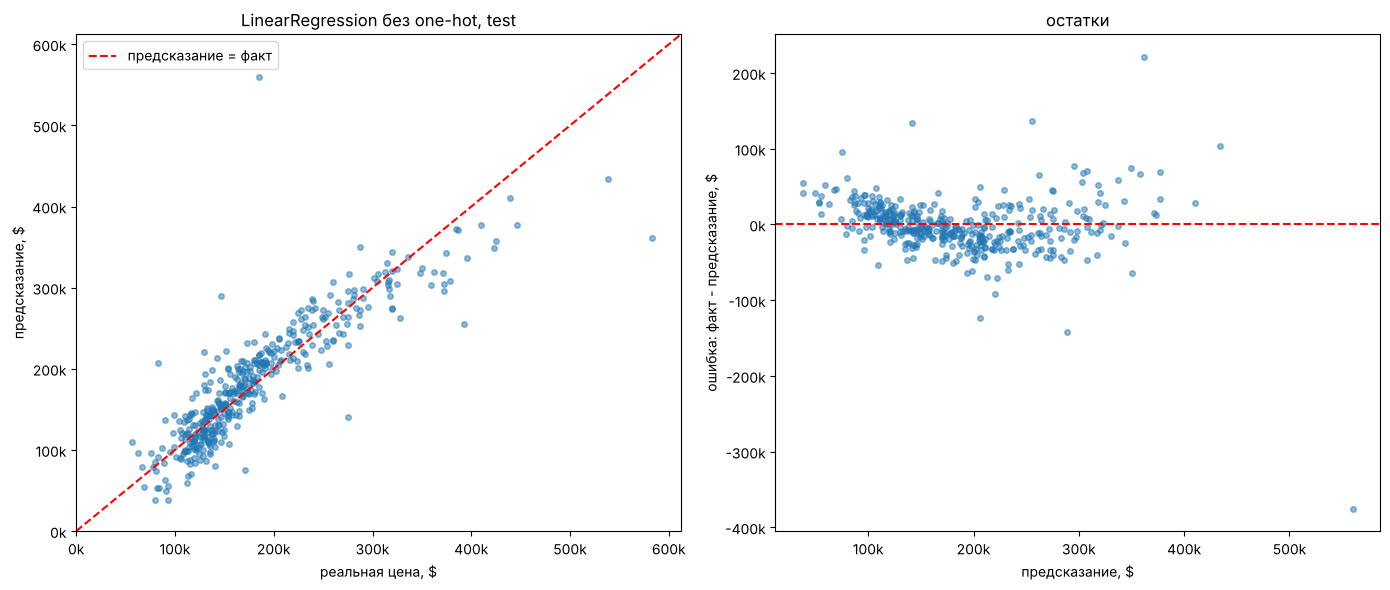

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
money = mticker.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k')

ax = axes[0]
ax.scatter(y_test, y_test_pred, alpha=0.5, s=16)
lims = [0, max(y_test.max(), y_test_pred.max()) * 1.05]
ax.plot(lims, lims, color='red', linestyle='--', label='предсказание = факт')
ax.set(xlim=lims, ylim=lims, xlabel='реальная цена, $', ylabel='предсказание, $',
       title='LinearRegression без one-hot, test')
ax.legend()

ax = axes[1]
resid = y_test - y_test_pred
ax.scatter(y_test_pred, resid, alpha=0.5, s=16)
ax.axhline(0, color='red', linestyle='--')
ax.set(xlabel='предсказание, $', ylabel='ошибка: факт - предсказание, $', title='остатки')

for ax in axes:
    ax.xaxis.set_major_formatter(money)
    ax.yaxis.set_major_formatter(money)
plt.tight_layout()
plt.show()

In [19]:
groups = pd.cut(y_test, [0, 120_000, 200_000, 300_000, np.inf], labels=['до 120k', '120-200k', '200-300k', 'от 300k'])
summary = pd.DataFrame({'домов': y_test.groupby(groups, observed=False).size(),
                        'средняя ошибка (факт - предск.), $': resid.groupby(groups, observed=False).mean().round(0),
                        'средняя |ошибка|, $': resid.abs().groupby(groups, observed=False).mean().round(0)})
print(summary.to_string(), end='\n\n')
pred_groups = pd.cut(pd.Series(y_test_pred, index=y_test.index), [0, 100_000, 150_000, 250_000, 350_000, np.inf],
                     labels=['до 100k', '100-150k', '150-250k', '250-350k', 'от 350k'])
print('средняя ошибка (факт - предск.) по группам ПРЕДСКАЗАНИЯ, $:')
print(resid.groupby(pred_groups, observed=False).agg(['count', 'mean']).round(0).to_string(), end='\n\n')
print('отрицательных предсказаний:', (y_test_pred < 0).sum(), '  минимальное предсказание:', round(y_test_pred.min()))
print('5 самых больших ошибок:')
worst = resid.abs().sort_values(ascending=False).index[:5]
pd.DataFrame({'факт': y_test[worst], 'предсказание': y_test_pred[X_test.index.get_indexer(worst)].round(0),
              'GrLivArea': X_test.loc[worst, 'GrLivArea'], 'OverallQual': X_test.loc[worst, 'OverallQual']})

           домов  средняя ошибка (факт - предск.), $  средняя |ошибка|, $
SalePrice                                                                
до 120k       73                                 6.0              21735.0
120-200k     221                             -7605.0              21970.0
200-300k      82                             -4589.0              22583.0
от 300k       38                             38156.0              41956.0

средняя ошибка (факт - предск.) по группам ПРЕДСКАЗАНИЯ, $:
          count     mean
до 100k      42  23647.0
100-150k    121   4760.0
150-250k    171 -14376.0
250-350k     70   2456.0
от 350k      10  11063.0

отрицательных предсказаний: 0   минимальное предсказание: 38031
5 самых больших ошибок:


,факт,предсказание,GrLivArea,OverallQual
493,184750.0,559847.0,4676.0,10
756,582933.0,361806.0,2822.0,9
1251,147000.0,289207.0,1795.0,8
1114,392500.0,255688.0,1652.0,8
1345,274970.0,141180.0,2201.0,6


**Ответ.**

Точки идут вдоль диагонали, основную зависимость модель уловила (R² 0.77). Но видно несколько проблем:

- **Дорогие дома недооцениваются.** Справа от 350 тыс. почти все точки ниже красной линии. У домов дороже 300 тыс. модель в среднем занижает цену на 38 тыс., и средняя ошибка у них 42 тыс. против примерно 22 тыс. у остальных групп. Реальная цена растет быстрее линейной (хороший большой дом дорожает непропорционально), а прямая этого не умеет. Это систематическая ошибка (bias) линейной модели.
- **Ошибка растет вместе с ценой.** Облако остатков расширяется вправо (гетероскедастичность), поэтому в MSE основной вклад дают дорогие дома.
- **В остатках дуга.** Если разбить по предсказанию: до 100 тыс. модель в среднем занижает на 24 тыс., в середине (150-250 тыс.) завышает на 14 тыс., выше снова занижает. Значит, зависимость нелинейная. Логарифм цены (вопрос 7) частично это исправляет.
- **Выбросы.** Точка вверху слева — дом 493: самая большая жилая площадь в данных (4676 кв. футов), высшая оценка качества 10, а продан за 184 750 $. Модель логично дает 560 тыс., ошибка 375 тыс. Это известный выброс Ames: огромные дома, проданные по частичной сделке. Автор набора советует убирать дома больше 4000 кв. футов. Обратный случай — дом 756: реально 583 тыс., предсказано 362 тыс.

Отрицательных предсказаний нет, минимальное 38 тыс.

## Вопрос 7 (дополнительно): log-преобразование

* Возьмите признаки с большой асимметрией (например, `skew > 0.75`) и примените к ним `np.log1p`.
* Попробуйте также логарифмировать `SalePrice` (не забудьте вернуть предсказания обратно через `np.expm1`).
* Как изменилась ошибка на test? Сравните с результатом без преобразования.

In [20]:
def log_predict(log_X, log_y):
    A, C = X_train.copy(), X_test.copy()
    if log_X:
        A[skewed_cols] = np.log1p(A[skewed_cols])
        C[skewed_cols] = np.log1p(C[skewed_cols])
    target = np.log1p(y_train) if log_y else y_train
    pred = LinearRegression().fit(A, target).predict(C)
    return np.expm1(pred) if log_y else pred

variants = {'без преобразований': (False, False), 'log признаков': (True, False),
            'log SalePrice': (False, True), 'log признаков + log SalePrice': (True, True)}
preds = {name: log_predict(*flags) for name, flags in variants.items()}

big = X_test['GrLivArea'].idxmax()
pos = X_test.index.get_loc(big)
keep = y_test.index != big
print(f'дом {big}: GrLivArea = {X_test.loc[big, "GrLivArea"]:.0f}, OverallQual = {X_test.loc[big, "OverallQual"]}, '
      f'реальная цена {y_test[big]:,.0f} $')

log_df = pd.DataFrame({name: {'MSE test': mean_squared_error(y_test, pred),
                              'RMSE test, $': np.sqrt(mean_squared_error(y_test, pred)),
                              'R2 test': r2_score(y_test, pred),
                              f'предсказание для дома {big}, $': pred[pos],
                              f'доля дома {big} в сумме квадратов ошибок': (y_test[big] - pred[pos]) ** 2 / ((y_test - pred) ** 2).sum(),
                              f'RMSE test без дома {big}, $': np.sqrt(mean_squared_error(y_test[keep], pred[keep]))}
                       for name, pred in preds.items()}).T
fmt = {c: '{:,.0f}' for c in log_df.columns}
fmt.update({'MSE test': '{:,.4g}', 'R2 test': '{:.4f}', f'доля дома {big} в сумме квадратов ошибок': '{:.0%}'})
log_df.style.format(fmt)

дом 493: GrLivArea = 4676, OverallQual = 10, реальная цена 184,750 $


,MSE test,"RMSE test, $",R2 test,"предсказание для дома 493, $",доля дома 493 в сумме квадратов ошибок,"RMSE test без дома 493, $"
без преобразований,1.372e+09,"37,043",0.7727,"559,847",25%,"32,169"
log признаков,1.324e+09,"36,389",0.7807,"463,113",14%,"33,760"
log SalePrice,1.776e+09,"42,145",0.7058,"827,459",56%,"27,934"
log признаков + log SalePrice,1.27e+09,"35,644",0.7896,"632,672",38%,"28,067"


**Ответ.**

На всем test:
- без преобразований: RMSE 37 043 $, R² 0.773;
- log признаков: 36 389 $, R² 0.781, чуть лучше;
- только log `SalePrice`: 42 145 $, R² 0.706, **хуже**;
- log признаков + log `SalePrice`: **35 644 $, R² 0.790**, лучший вариант. MSE на 7% меньше, чем без преобразований.

Почему log одной цены «хуже», видно по дому 493 из вопроса 6. С log цены модель становится мультипликативной: каждый лишний квадратный фут умножает цену, а не прибавляет. У дома с рекордными 4676 кв. футов это дает экспоненту: предсказание 827 тыс. при реальных 185 тыс. Один этот дом дает 56% всей суммы квадратов ошибок этой модели. Если его убрать, картина обратная: без преобразований 32.2 тыс., log цены **27.9 тыс.**, log признаков + log цены 28.1 тыс. То есть на обычных домах log цены уменьшает ошибку примерно на 13%. Он исправляет то, что видно в вопросе 6: дорогие дома больше не занижаются, а ошибка становится относительной (в процентах от цены), а не в долларах.

Когда логарифмируются и площади, получается модель «log-log»: цена растет как степень площади, а не как экспонента. Поэтому выброс портит ее меньше (633 тыс. вместо 827 тыс.), и это лучший вариант на всем test. Вывод: логарифм асимметричных признаков и цели помогает, но выбросы вроде дома 493 лучше убирать до обучения.

## Вопрос 8 (дополнительно): кросс-валидация

Оцените модель на неоднородных данных (без one-hot) с помощью `cross_val_score` и `cv=5`. Насколько стабильна ошибка по фолдам и чем это лучше одного разбиения train/test?

In [21]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
mse_folds = -cross_val_score(LinearRegression(), X_data, y_data, cv=kf, scoring='neg_mean_squared_error')

cv_df = pd.DataFrame({'MSE': mse_folds, 'RMSE, $': np.sqrt(mse_folds)}, index=[f'фолд {i}' for i in range(1, 6)])
print(cv_df.round(0).to_string(), end='\n\n')
print(f'MSE: среднее {mse_folds.mean():,.4g}, std {mse_folds.std():,.4g}')
print(f'RMSE: среднее {np.sqrt(mse_folds).mean():,.0f} $, от {np.sqrt(mse_folds).min():,.0f} до {np.sqrt(mse_folds).max():,.0f} $')

huge = X_data.index[X_data['GrLivArea'] > 4000]
for i, (_, val_idx) in enumerate(kf.split(X_data), start=1):
    in_fold = [h for h in huge if h in X_data.index[val_idx]]
    if in_fold:
        print(f'фолд {i}:', ', '.join(f'дом {h} ({X_data.loc[h, "GrLivArea"]:.0f} кв. футов, {y_data[h]:,.0f} $)' for h in in_fold))

                 MSE  RMSE, $
фолд 1  1.480325e+09  38475.0
фолд 2  1.098071e+09  33137.0
фолд 3  1.226189e+09  35017.0
фолд 4  2.300932e+09  47968.0
фолд 5  8.619421e+08  29359.0

MSE: среднее 1.393e+09, std 4.957e+08
RMSE: среднее 36,791 $, от 29,359 до 47,968 $
фолд 1: дом 493 (4676 кв. футов, 184,750 $)
фолд 3: дом 649 (4316 кв. футов, 755,000 $)
фолд 4: дом 1115 (4476 кв. футов, 745,000 $), дом 1226 (5642 кв. футов, 160,000 $)


In [22]:
single = []
for rs in range(20):
    a, c, b, d = train_test_split(X_data, y_data, test_size=0.3, random_state=rs)
    single.append(mean_squared_error(d, LinearRegression().fit(a, b).predict(c)))
single = np.array(single)
print(f'одно разбиение 70/30, 20 вариантов: MSE от {single.min():,.4g} до {single.max():,.4g} '
      f'(RMSE от {np.sqrt(single.min()):,.0f} до {np.sqrt(single.max()):,.0f} $)')
print(f'наше разбиение random_state=42: MSE {mean_squared_error(y_test, y_test_pred):,.4g}')

одно разбиение 70/30, 20 вариантов: MSE от 8.858e+08 до 2.641e+09 (RMSE от 29,762 до 51,392 $)
наше разбиение random_state=42: MSE 1.372e+09


**Ответ.**

На 5 фолдах (с перемешиванием) ошибка заметно гуляет: RMSE от 29.4 до 48.0 тыс. $, в среднем 36.8 тыс. MSE 1.39e9 ± 0.50e9, то есть std около трети от среднего. Самый плохой фолд 4 (48 тыс.): в него попал дом 1226 (5642 кв. фута, продан за 160 тыс. $), такой же выброс, как дом 493 из вопроса 6.

Одно разбиение 70/30 — по сути лотерея. Та же модель на 20 разных `random_state` дает MSE от 0.89e9 до 2.64e9, разница в 3 раза (RMSE от 29.8 до 51.4 тыс. $). Наше разбиение `random_state=42` (1.37e9) случайно оказалось близко к среднему, но могло быть и 0.9e9, и 2.6e9.

Чем кросс-валидация лучше:
- каждый дом ровно один раз попадает в валидацию, и итог — среднее по 5 оценкам, а не одна случайная;
- видно разброс (std), то есть насколько оценке вообще можно верить;
- все данные используются и для обучения, и для проверки, а при 1379 домах это важно;
- по ней честно выбирают гиперпараметры (как k в лабе 2), не трогая отложенный test.

Минус один: модель обучается 5 раз вместо одного. Для линейной регрессии на 1379 строках это ничего не стоит.